**Question 1**

(a)

Let the neural network output be $$g(x)=(g_1(x),g_2(x))$$ We use the identity function for the conditional mean and the exponential function for the conditional standard deviation:

$$
f_\mu(x)=g_1(x),\qquad f_\sigma(x)=\exp(g_2(x)).
$$

The identity function allows the mean to take any real value, while the exponential function ensures that the predicted standard deviation is always positive.

(b)

Under the assumption that

$$
Y\mid X\sim \mathcal N(f_\mu(x),f_\sigma(x)^2),
$$

the probability density function is:

$$
p(y_i\mid x_i)=
\frac{1}{\sqrt{2\pi}\sigma_i}
\exp\left(
-\frac{(y_i-\mu_i)^2}{2\sigma_i^2}
\right)
$$

Then, we take the negative log-likelihood $L_i=-\log p(y_i\mid x_i)$ to get the formula for this problem:

$$
L_i=
-\log\left[
\frac{1}{\sqrt{2\pi}\sigma_i}
\exp\left(
-\frac{(y_i-\mu_i)^2}{2\sigma_i^2}
\right)
\right]
$$

Finally, we can calculate the overall loss function:

$$
\mathcal L=
\frac1n\sum_{i=1}^n
\left[
\frac12\log(2\pi)
+\log f_\sigma(x_i)
+\frac{(y_i-f_\mu(x_i))^2}{2f_\sigma(x_i)^2}
\right].
$$

(c)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    accuracy_score,
    brier_score_loss
)

from sklearn.linear_model import LinearRegression
from scipy.stats import norm

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [2]:
df = pd.read_parquet(
    "taxi_trips.parquet",
    engine="fastparquet"
)

display(df.head())

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

display(df.describe())

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,min_of_day,day_of_week,day_of_year
187173,0.270744,1.425051,0.466831,0.776192,7.965142,-0.942057,-1.047619,1.180855
179655,0.085681,0.306079,-0.226274,0.124111,10.680277,0.778703,-1.047619,-0.311290
120048,-0.555533,-0.934806,-0.022489,-0.548561,5.716184,-1.183016,-1.047619,1.316504
62587,0.069718,0.035804,0.258900,0.317284,4.266709,-0.908008,0.481657,0.018144
212063,-0.234482,0.074616,0.115836,0.258310,11.629685,1.066806,-0.537860,0.521985


Dataset shape: (523554, 8)

Column names:
['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'trip_duration', 'min_of_day', 'day_of_week', 'day_of_year']

Missing values:
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
trip_duration        0
min_of_day           0
day_of_week          0
day_of_year          0
dtype: int64


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,min_of_day,day_of_week,day_of_year
count,5.235540e+05,5.235540e+05,5.235540e+05,5.235540e+05,523554.000000,5.235540e+05,5.235540e+05,5.235540e+05
mean,-1.748678e-10,-1.748678e-10,5.828926e-11,2.914463e-10,10.413046,1.165785e-10,1.393113e-08,9.326282e-10
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,7.754068,1.000000e+00,1.000000e+00,1.000000e+00
min,-3.336066e+01,-1.429924e+01,-3.347844e+01,-1.274645e+01,0.033386,-2.209709e+00,-1.557377e+00,-1.745299e+00
25%,-5.369088e-01,-5.731353e-01,-5.754919e-01,-5.540238e-01,4.749882,-7.168128e-01,-1.047619e+00,-8.538882e-01
50%,-1.540720e-01,7.132973e-02,-1.468923e-01,5.897350e-02,8.631456,1.003516e-01,-2.810149e-02,-1.234100e-03
75%,3.703701e-01,6.306590e-01,4.286219e-01,6.097745e-01,13.928152,8.389425e-01,9.914155e-01,8.514200e-01
max,2.937226e+01,1.327707e+01,5.266416e+01,2.087581e+01,227.942612,1.559200e+00,1.501174e+00,1.762210e+00


In [3]:
possible_targets = [
    "trip_duration",
    "trip_duration_minutes",
    "duration",
    "duration_minutes"
]

target_col = next(
    (c for c in possible_targets if c in df.columns),
    None
)

if target_col is None:
    raise ValueError(
        "Please inspect df.columns and set target_col "
        "to the trip duration column."
    )

print("Target column:", target_col)

X = df.drop(columns=[target_col]).to_numpy(
    dtype=np.float32
)

y = df[target_col].to_numpy(
    dtype=np.float32
)

assert X.shape[1] == 7
assert np.isfinite(X).all()
assert np.isfinite(y).all()

Target column: trip_duration


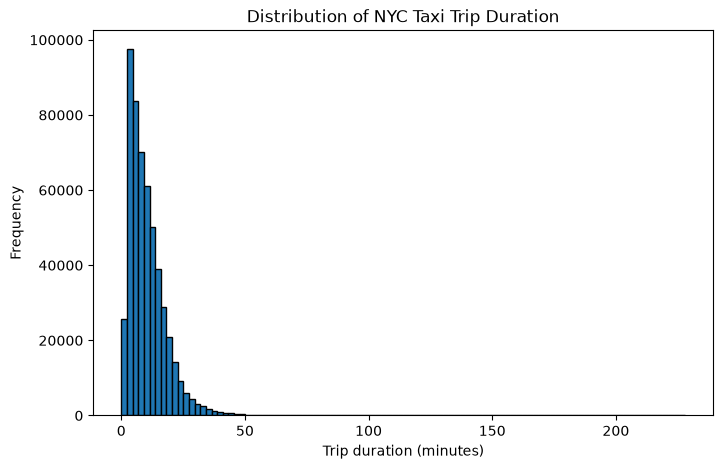

Mean: 10.413046
Median: 8.631456
Standard deviation: 7.7540607
Minimum: 0.03338592
Maximum: 227.94261


In [4]:
plt.figure(figsize=(8, 5))

plt.hist(y, bins=100, edgecolor="black")

plt.xlabel("Trip duration (minutes)")
plt.ylabel("Frequency")
plt.title("Distribution of NYC Taxi Trip Duration")

plt.show()

print("Mean:", np.mean(y))
print("Median:", np.median(y))
print("Standard deviation:", np.std(y))
print("Minimum:", np.min(y))
print("Maximum:", np.max(y))

In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (366487, 7)
Validation: (78533, 7)
Test: (78534, 7)


In [6]:
baseline_mean = np.mean(y_train)

baseline_pred = np.full_like(
    y_test,
    baseline_mean
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_mse = mean_squared_error(
    y_test,
    baseline_pred
)

print("Mean Baseline MAE:", baseline_mae)
print("Mean Baseline MSE:", baseline_mse)

Mean Baseline MAE: 5.682144641876221
Mean Baseline MSE: 60.16938018798828


In [7]:
lr = LinearRegression()

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

lr_mae = mean_absolute_error(
    y_test,
    lr_pred
)

lr_mse = mean_squared_error(
    y_test,
    lr_pred
)

print("Linear Regression MAE:", lr_mae)
print("Linear Regression MSE:", lr_mse)

Linear Regression MAE: 5.56967306137085
Linear Regression MSE: 56.91889953613281


In [8]:
def gaussian_nll_numpy(y_true, mu, sigma):
    sigma = np.maximum(sigma, 1e-4)

    return np.mean(
        0.5 * np.log(2 * np.pi)
        + np.log(sigma)
        + 0.5 * ((y_true - mu) / sigma) ** 2
    )


baseline_sigma = np.std(y_train)

baseline_nll = gaussian_nll_numpy(
    y_test,
    np.full_like(y_test, baseline_mean),
    np.full_like(y_test, baseline_sigma)
)

print("Constant Gaussian Baseline NLL:", baseline_nll)

Constant Gaussian Baseline NLL: 3.467520442765214


In [9]:
class GaussianMLP(nn.Module):

    def __init__(self, input_dim=7):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 2)
        )

    def forward(self, x):

        output = self.network(x)

        mu = output[:, 0]

        raw_sigma = output[:, 1]

        sigma = torch.exp(raw_sigma)
        return mu, sigma

In [10]:
def gaussian_nll(mu, sigma, y):

    loss = (
        0.5 * torch.log(
            2 * torch.pi * sigma**2
        )
        + (y - mu)**2 / (2 * sigma**2)
    )

    return loss.mean()

In [11]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False
)

In [12]:
import copy

model = GaussianMLP(input_dim=X_train.shape[1]).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 100
patience = 12

best_val_loss = float("inf")
best_state = None
patience_counter = 0

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        mu, sigma = model(xb)

        loss = gaussian_nll(mu, sigma, yb)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * len(xb)

    train_loss = running_loss / len(train_dataset)

    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for xb, yb in val_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            mu, sigma = model(xb)

            loss = gaussian_nll(mu, sigma, yb)

            running_val_loss += loss.item() * len(xb)

    val_loss = running_val_loss / len(val_dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_state = copy.deepcopy(
            model.state_dict()
        )

        patience_counter = 0

    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch {epoch+1}: "
            f"Train NLL = {train_loss:.4f}, "
            f"Val NLL = {val_loss:.4f}"
        )

    if patience_counter >= patience:
        print("Early stopping triggered.")
        break

model.load_state_dict(best_state)
model.eval()

Epoch 10: Train NLL = 2.6901, Val NLL = 2.7017
Epoch 20: Train NLL = 2.6482, Val NLL = 2.6619
Epoch 30: Train NLL = 2.6354, Val NLL = 2.6625
Epoch 40: Train NLL = 2.6167, Val NLL = 2.6442
Epoch 50: Train NLL = 2.6056, Val NLL = 2.6328
Epoch 60: Train NLL = 2.5920, Val NLL = 2.6238
Epoch 70: Train NLL = 2.5846, Val NLL = 2.6139
Epoch 80: Train NLL = 2.5776, Val NLL = 2.6167
Epoch 90: Train NLL = 2.5755, Val NLL = 2.6215
Epoch 100: Train NLL = 2.5702, Val NLL = 2.6086


GaussianMLP(
  (network): Sequential(
    (0): Linear(in_features=7, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)

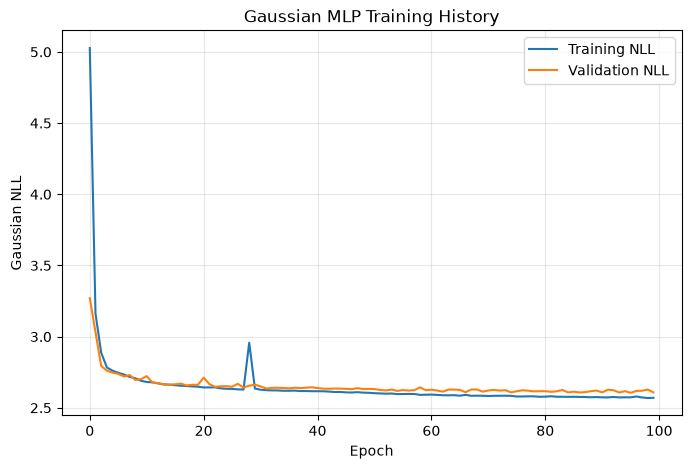

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training NLL"
)

plt.plot(
    val_losses,
    label="Validation NLL"
)

plt.xlabel("Epoch")
plt.ylabel("Gaussian NLL")
plt.title("Gaussian MLP Training History")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [14]:
X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
).to(device)

with torch.no_grad():

    mu_test, sigma_test = model(X_test_tensor)

mu_test = mu_test.cpu().numpy()
sigma_test = sigma_test.cpu().numpy()

test_mae = mean_absolute_error(
    y_test,
    mu_test
)

test_mse = mean_squared_error(
    y_test,
    mu_test
)

test_nll = gaussian_nll_numpy(
    y_test,
    mu_test,
    sigma_test
)

results_q1c = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Linear Regression",
        "Gaussian MLP"
    ],
    "Test MAE": [
        baseline_mae,
        lr_mae,
        test_mae
    ],
    "Test MSE": [
        baseline_mse,
        lr_mse,
        test_mse
    ]
})

display(results_q1c)

print("Gaussian MLP Test NLL:", test_nll)
print("Constant Gaussian Baseline NLL:", baseline_nll)

,Model,Test MAE,Test MSE
0,Mean Baseline,5.682145,60.169380
1,Linear Regression,5.569673,56.918900
2,Gaussian MLP,2.491764,15.808531


Gaussian MLP Test NLL: 2.747731255906597
Constant Gaussian Baseline NLL: 3.467520442765214


The Gaussian MLP showed stable convergence during training. Both the training and validation NLL decreased rapidly during the first several epochs and gradually stabilized.

On the test set, the Gaussian MLP achieved an MAE of 2.4918 and an MSE of 15.8085, outperforming both the mean baseline and linear regression.

The Gaussian MLP achieved a test NLL of 2.7477, while the test NLL for the constant Gaussian baseline was 3.4675. This indicates that the model provides better predictions under the Gaussian MLP.

(d)

In [15]:
from scipy.stats import norm

prob_under_45 = norm.cdf(
    (45 - mu_test) / sigma_test
)

print("First 10 probabilities:")
print(prob_under_45[:10])

First 10 probabilities:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [16]:
print("Actual trip duration statistics:")

print("Mean:", np.mean(y_test))
print("Median:", np.median(y_test))
print("Maximum:", np.max(y_test))

print(
    "Percentage of trips under 45 min:",
    np.mean(y_test < 45) * 100
)

print(
    "Number of trips >= 45 min:",
    np.sum(y_test >= 45)
)

Actual trip duration statistics:
Mean: 10.403939
Median: 8.631456
Maximum: 173.34428
Percentage of trips under 45 min: 99.5543331550666
Number of trips >= 45 min: 350


The predicted probabilities are mostly close to 1 because the dataset is highly imbalanced. Approximately 99.55% of test trips take less than 45 minutes.

Since the model predicts the conditional mean $f_\mu(x)$ and standard deviation $f_\sigma(x)$, we can use the CDF to calculate the probability that a trip takes less than 45 minutes. We apply this formula to each observation using the mean and standard deviation predicted by our Gaussian MLP.

(e)

In [17]:
from sklearn.metrics import brier_score_loss, accuracy_score
import numpy as np
import pandas as pd

y_test_binary = (y_test < 45).astype(int)

y_pred_binary = (prob_under_45 >= 0.5).astype(int)

mlp_brier = brier_score_loss(
    y_test_binary,
    prob_under_45
)

mlp_accuracy = accuracy_score(
    y_test_binary,
    y_pred_binary
)

baseline_prob = np.mean(y_train < 45)

baseline_probs = np.full(
    len(y_test),
    baseline_prob
)

baseline_pred = (
    baseline_probs >= 0.5
).astype(int)

baseline_brier = brier_score_loss(
    y_test_binary,
    baseline_probs
)

baseline_accuracy = accuracy_score(
    y_test_binary,
    baseline_pred
)

results = pd.DataFrame({
    "Model": [
        "Constant Probability Baseline",
        "Gaussian MLP"
    ],
    "Brier Score": [
        baseline_brier,
        mlp_brier
    ],
    "Accuracy": [
        baseline_accuracy,
        mlp_accuracy
    ]
})

display(results)

,Model,Brier Score,Accuracy
0,Constant Probability Baseline,0.004437,0.995543
1,Gaussian MLP,0.002806,0.996817


The Gaussian MLP achieved a Brier score of 0.00281 and an accuracy of 0.997. We also compared its performance with a constant probability baseline. Since approximately 99.55% of the test trips took less than 45 minutes, the binary classification task is highly imbalanced. Therefore, the model always predicts trips to be under 45 minutes would achieve approximately 99.55% accuracy.

**Question 2**

(a)

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

df = pd.read_csv("retail.csv")

print("Dataset shape:", df.shape)

display(df.head())

print(df.info())

print(df.isna().sum())

Dataset shape: (397924, 3)


,Quantity,StockCode,CustomerID
0,6,85123A,17850.0
1,6,71053,17850.0
2,8,84406B,17850.0
3,6,84029G,17850.0
4,6,84029E,17850.0


<class 'pandas.DataFrame'>
RangeIndex: 397924 entries, 0 to 397923
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Quantity    397924 non-null  int64  
 1   StockCode   397924 non-null  str    
 2   CustomerID  397924 non-null  float64
dtypes: float64(1), int64(1), str(1)
memory usage: 11.0 MB
None
Quantity      0
StockCode     0
CustomerID    0
dtype: int64


In [19]:
stock_cardinality = df["StockCode"].nunique()

customer_cardinality = df["CustomerID"].nunique()

print("Unique StockCodes:", stock_cardinality)

print("Unique CustomerIDs:", customer_cardinality)

print(
    "Total one-hot dimensions:",
    stock_cardinality + customer_cardinality
)

Unique StockCodes: 3665
Unique CustomerIDs: 4339
Total one-hot dimensions: 8004


The dataset contains 397,924 transactions, with 3,665 unique StockCode values and 4,339 unique CustomerID values. Applying one-hot encoding to both categorical variables would result in 8,004 features. Although sparse one-hot encoding is technically feasible, it produces a high-dimensional representation. Target encoding and embedding layers provide more compact alternatives.

In [20]:
df["StockCode"] = df["StockCode"].astype(str)

df["CustomerID"] = (
    df["CustomerID"]
    .astype("int64")
    .astype(str)
)

print(df.dtypes)

Quantity      int64
StockCode       str
CustomerID      str
dtype: object


In [21]:
print(df["Quantity"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
))

count    397924.000000
mean         13.021823
std         180.420210
min           1.000000
50%           6.000000
90%          24.000000
95%          36.000000
99%         120.000000
max       80995.000000
Name: Quantity, dtype: float64


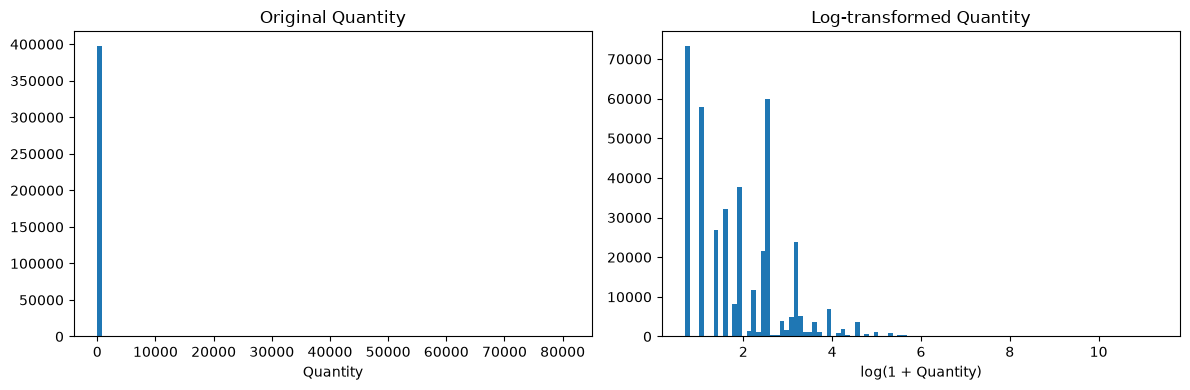

In [22]:
# distribution is skew to the right, using log transformation
df["log_quantity"] = np.log1p(
    df["Quantity"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    df["Quantity"],
    bins=100
)

axes[0].set_title("Original Quantity")
axes[0].set_xlabel("Quantity")

axes[1].hist(
    df["log_quantity"],
    bins=100
)

axes[1].set_title("Log-transformed Quantity")
axes[1].set_xlabel("log(1 + Quantity)")

plt.tight_layout()
plt.show()

In [23]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (278546, 4)
Validation: (59689, 4)
Test: (59689, 4)


(b)

In [24]:
import numpy as np
import pandas as pd

from category_encoders import TargetEncoder
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

In [25]:
cat_cols = ["StockCode", "CustomerID"]

X_train = train_df[cat_cols].copy()
X_val = val_df[cat_cols].copy()
X_test = test_df[cat_cols].copy()

y_train = np.log1p(
    train_df["Quantity"].to_numpy()
)

y_val = np.log1p(
    val_df["Quantity"].to_numpy()
)

y_test = test_df["Quantity"].to_numpy()

In [26]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

X_train_encoded = pd.DataFrame(
    index=X_train.index,
    columns=cat_cols,
    dtype=float
)

for train_idx, holdout_idx in kf.split(X_train):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_holdout = X_train.iloc[holdout_idx]

    y_fold_train = y_train[train_idx]

    encoder_fold = TargetEncoder(
        cols=cat_cols,
        smoothing=20
    )

    encoder_fold.fit(
        X_fold_train,
        y_fold_train
    )

    X_train_encoded.iloc[holdout_idx] = (
        encoder_fold.transform(
            X_fold_holdout
        ).to_numpy()
    )
display(X_train_encoded.head())

,StockCode,CustomerID
120821,2.806168,2.112817
279460,1.143584,1.106471
249637,1.290491,1.627186
84115,1.968644,2.366400
36211,1.385458,1.498261


In [27]:
encoder = TargetEncoder(
    cols=cat_cols,
    smoothing=20
)

encoder.fit(
    X_train,
    y_train
)

X_val_encoded = encoder.transform(
    X_val
)

X_test_encoded = encoder.transform(
    X_test
)

In [28]:
ridge_model = Ridge(
    alpha=1.0
)

ridge_model.fit(
    X_train_encoded,
    y_train
)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [29]:
val_pred_log = ridge_model.predict(
    X_val_encoded
)

val_pred = np.maximum(
    np.expm1(val_pred_log),
    0
)

val_mae = mean_absolute_error(
    val_df["Quantity"],
    val_pred
)

val_rmse = np.sqrt(
    mean_squared_error(
        val_df["Quantity"],
        val_pred
    )
)

print("Validation MAE:", val_mae)
print("Validation RMSE:", val_rmse)

Validation MAE: 7.237407837022175
Validation RMSE: 32.817109139951185


In [30]:
test_pred_log = ridge_model.predict(
    X_test_encoded
)

test_pred = np.maximum(
    np.expm1(test_pred_log),
    0
)

In [31]:
test_mae = mean_absolute_error(
    y_test,
    test_pred
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test_pred
    )
)

test_rmsle = np.sqrt(
    mean_squared_error(
        np.log1p(y_test),
        np.log1p(test_pred)
    )
)

print("Target Encoding + Ridge Regression")

print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)
print("Test RMSLE:", test_rmsle)

Target Encoding + Ridge Regression
Test MAE: 6.978288895821127
Test RMSE: 34.52867948500246
Test RMSLE: 0.6014400415775477


In [32]:
q2b_results = pd.DataFrame({
    "Model": [
        "Target Encoding + Ridge"
    ],
    "Test MAE": [
        test_mae
    ],
    "Test RMSE": [
        test_rmse
    ],
    "Test RMSLE": [
        test_rmsle
    ]
})

display(q2b_results)

,Model,Test MAE,Test RMSE,Test RMSLE
0,Target Encoding + Ridge,6.978289,34.528679,0.60144


The model achieved a test MAE of 6.978, RMSE of 34.529, and RMSLE of 0.601.

(c)

In [33]:
def encode_categories(train_df, val_df, test_df, col):

    unique_values = train_df[col].unique()

    mapping = {
        value: idx + 1
        for idx, value in enumerate(unique_values)
    }

    train_ids = (
        train_df[col]
        .map(mapping)
        .fillna(0)
        .astype(int)
        .to_numpy()
    )

    val_ids = (
        val_df[col]
        .map(mapping)
        .fillna(0)
        .astype(int)
        .to_numpy()
    )

    test_ids = (
        test_df[col]
        .map(mapping)
        .fillna(0)
        .astype(int)
        .to_numpy()
    )

    return train_ids, val_ids, test_ids, len(mapping) + 1

In [34]:
train_stock, val_stock, test_stock, n_stock = (
    encode_categories(
        train_df,
        val_df,
        test_df,
        "StockCode"
    )
)

train_customer, val_customer, test_customer, n_customer = (
    encode_categories(
        train_df,
        val_df,
        test_df,
        "CustomerID"
    )
)

print("Stock vocabulary size:", n_stock)
print("Customer vocabulary size:", n_customer)

Stock vocabulary size: 3596
Customer vocabulary size: 4312


In [35]:
def make_loader(
    stock,
    customer,
    target,
    batch_size=1024,
    shuffle=False
):

    dataset = TensorDataset(

        torch.tensor(
            stock,
            dtype=torch.long
        ),

        torch.tensor(
            customer,
            dtype=torch.long
        ),

        torch.tensor(
            target,
            dtype=torch.float32
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )

    return loader

In [37]:
y_train_log = np.log1p(train_df["Quantity"].to_numpy())
y_val_log = np.log1p(val_df["Quantity"].to_numpy())

y_test_original = test_df["Quantity"].to_numpy()
y_test_log = np.log1p(y_test_original)

In [38]:
train_loader = make_loader(
    train_stock,
    train_customer,
    y_train_log,
    shuffle=True
)

val_loader = make_loader(
    val_stock,
    val_customer,
    y_val_log
)

test_loader = make_loader(
    test_stock,
    test_customer,
    y_test_log
)

In [39]:
class EmbeddingNN(nn.Module):

    def __init__(
        self,
        n_stock,
        n_customer,
        embedding_dim=16
    ):

        super().__init__()

        self.stock_embedding = nn.Embedding(
            num_embeddings=n_stock,
            embedding_dim=embedding_dim
        )

        self.customer_embedding = nn.Embedding(
            num_embeddings=n_customer,
            embedding_dim=embedding_dim
        )

        self.mlp = nn.Sequential(

            nn.Linear(embedding_dim * 2, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, stock, customer):

        stock_vec = self.stock_embedding(stock)

        customer_vec = self.customer_embedding(customer)

        combined = torch.cat(
            [stock_vec, customer_vec],
            dim=1
        )

        prediction = self.mlp(combined)

        return prediction.squeeze(1)

In [40]:
model = EmbeddingNN(
    n_stock=n_stock,
    n_customer=n_customer,
    embedding_dim=16
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

EmbeddingNN(
  (stock_embedding): Embedding(3596, 16)
  (customer_embedding): Embedding(4312, 16)
  (mlp): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [41]:
num_epochs = 30
patience = 5

best_val_loss = float("inf")
best_state = None
wait = 0

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    model.train()

    total_train_loss = 0.0

    for stock, customer, target in train_loader:

        stock = stock.to(device)
        customer = customer.to(device)
        target = target.to(device)

        optimizer.zero_grad()

        prediction = model(
            stock,
            customer
        )

        loss = criterion(
            prediction,
            target
        )

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item() * len(target)

    train_loss = total_train_loss / len(
        train_loader.dataset
    )

    model.eval()

    total_val_loss = 0.0

    with torch.no_grad():

        for stock, customer, target in val_loader:

            stock = stock.to(device)
            customer = customer.to(device)
            target = target.to(device)

            prediction = model(
                stock,
                customer
            )

            loss = criterion(
                prediction,
                target
            )

            total_val_loss += loss.item() * len(target)

    val_loss = total_val_loss / len(
        val_loader.dataset
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train MSE: {train_loss:.4f} | "
        f"Val MSE: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_state = copy.deepcopy(
            model.state_dict()
        )

        wait = 0

    else:
        wait += 1

    if wait >= patience:
        print("Early stopping triggered.")
        break

model.load_state_dict(best_state)
model.eval()

print("Best Validation MSE:", best_val_loss)

Epoch 01 | Train MSE: 1.2408 | Val MSE: 0.8431
Epoch 02 | Train MSE: 0.7455 | Val MSE: 0.6514
Epoch 03 | Train MSE: 0.5736 | Val MSE: 0.5135
Epoch 04 | Train MSE: 0.4578 | Val MSE: 0.4309
Epoch 05 | Train MSE: 0.3899 | Val MSE: 0.3829
Epoch 06 | Train MSE: 0.3510 | Val MSE: 0.3544
Epoch 07 | Train MSE: 0.3277 | Val MSE: 0.3375
Epoch 08 | Train MSE: 0.3127 | Val MSE: 0.3265
Epoch 09 | Train MSE: 0.3027 | Val MSE: 0.3184
Epoch 10 | Train MSE: 0.2958 | Val MSE: 0.3139
Epoch 11 | Train MSE: 0.2902 | Val MSE: 0.3095
Epoch 12 | Train MSE: 0.2865 | Val MSE: 0.3061
Epoch 13 | Train MSE: 0.2832 | Val MSE: 0.3052
Epoch 14 | Train MSE: 0.2801 | Val MSE: 0.3015
Epoch 15 | Train MSE: 0.2774 | Val MSE: 0.3005
Epoch 16 | Train MSE: 0.2755 | Val MSE: 0.2991
Epoch 17 | Train MSE: 0.2735 | Val MSE: 0.2974
Epoch 18 | Train MSE: 0.2717 | Val MSE: 0.3023
Epoch 19 | Train MSE: 0.2698 | Val MSE: 0.2991
Epoch 20 | Train MSE: 0.2687 | Val MSE: 0.2979
Epoch 21 | Train MSE: 0.2667 | Val MSE: 0.2950
Epoch 22 | Tr

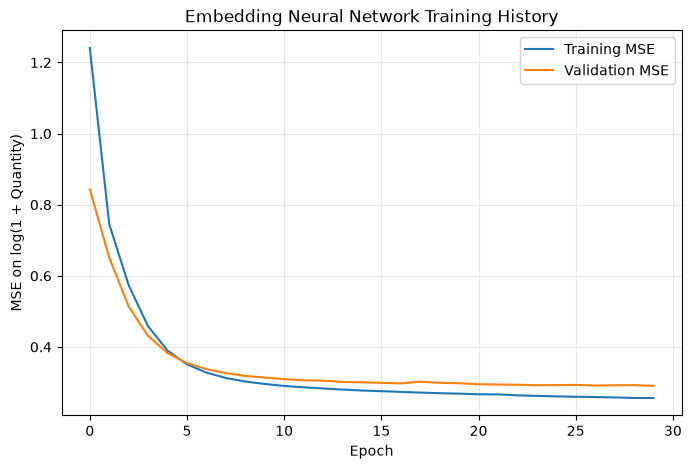

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training MSE"
)

plt.plot(
    val_losses,
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("MSE on log(1 + Quantity)")
plt.title("Embedding Neural Network Training History")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [43]:
model.eval()

test_predictions_log = []

with torch.no_grad():

    for stock, customer, target in test_loader:

        stock = stock.to(device)
        customer = customer.to(device)

        prediction = model(
            stock,
            customer
        )

        test_predictions_log.append(
            prediction.cpu().numpy()
        )

test_predictions_log = np.concatenate(
    test_predictions_log
)

test_predictions = np.maximum(
    np.expm1(test_predictions_log),
    0
)

In [44]:
test_mae = mean_absolute_error(
    y_test_original,
    test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test_original,
        test_predictions
    )
)

test_rmsle = np.sqrt(
    mean_squared_error(
        np.log1p(y_test_original),
        np.log1p(test_predictions)
    )
)

print("Embedding Neural Network Results")

print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)
print("Test RMSLE:", test_rmsle)

Embedding Neural Network Results
Test MAE: 6.20442008972168
Test RMSE: 30.32533656198487
Test RMSLE: 0.5392610039334189


In [45]:
q2c_results = pd.DataFrame({
    "Model": ["Embedding NN"],
    "Test MAE": [test_mae],
    "Test RMSE": [test_rmse],
    "Test RMSLE": [test_rmsle]
})

comparison_q2bc = pd.concat(
    [
        q2b_results,
        q2c_results
    ],
    ignore_index=True
)

display(comparison_q2bc)

,Model,Test MAE,Test RMSE,Test RMSLE
0,Target Encoding + Ridge,6.978289,34.528679,0.601440
1,Embedding NN,6.204420,30.325337,0.539261


On the held-out test set, the embedding neural network achieved an MAE of 6.204, RMSE of 30.325, and RMSLE of 0.539. Compared with the target encoding model, the embedding model performed better based on these three metrics.

(d)

In [46]:
X_train_te = X_train_encoded.to_numpy(dtype=np.float32)
X_val_te = X_val_encoded.to_numpy(dtype=np.float32)
X_test_te = X_test_encoded.to_numpy(dtype=np.float32)

In [47]:
def make_hybrid_loader(
    stock,
    customer,
    te_features,
    target,
    batch_size=1024,
    shuffle=False
):
    dataset = TensorDataset(
        torch.tensor(stock, dtype=torch.long),
        torch.tensor(customer, dtype=torch.long),
        torch.tensor(te_features, dtype=torch.float32),
        torch.tensor(target, dtype=torch.float32)
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )

In [48]:
hybrid_train_loader = make_hybrid_loader(
    train_stock,
    train_customer,
    X_train_te,
    y_train_log,
    shuffle=True
)

hybrid_val_loader = make_hybrid_loader(
    val_stock,
    val_customer,
    X_val_te,
    y_val_log
)

hybrid_test_loader = make_hybrid_loader(
    test_stock,
    test_customer,
    X_test_te,
    np.log1p(y_test_original)
)

In [49]:
class HybridNN(nn.Module):

    def __init__(
        self,
        n_stock,
        n_customer,
        embedding_dim=16
    ):
        super().__init__()

        self.stock_embedding = nn.Embedding(
            n_stock,
            embedding_dim
        )

        self.customer_embedding = nn.Embedding(
            n_customer,
            embedding_dim
        )

        self.mlp = nn.Sequential(
            nn.Linear(embedding_dim * 2 + 2, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, stock, customer, target_encoded):

        stock_vec = self.stock_embedding(stock)
        customer_vec = self.customer_embedding(customer)

        combined = torch.cat(
            [stock_vec, customer_vec, target_encoded],
            dim=1
        )

        prediction = self.mlp(combined)

        return prediction.squeeze(1)

In [50]:
import copy

torch.manual_seed(42)

hybrid_model = HybridNN(
    n_stock=n_stock,
    n_customer=n_customer,
    embedding_dim=16
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    hybrid_model.parameters(),
    lr=0.001
)

print(hybrid_model)

HybridNN(
  (stock_embedding): Embedding(3596, 16)
  (customer_embedding): Embedding(4312, 16)
  (mlp): Sequential(
    (0): Linear(in_features=34, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [51]:
num_epochs = 30
patience = 5

best_val_loss = float("inf")
best_state = None
wait = 0

hybrid_train_losses = []
hybrid_val_losses = []

for epoch in range(num_epochs):

    hybrid_model.train()

    total_train_loss = 0.0

    for stock, customer, te, target in hybrid_train_loader:

        stock = stock.to(device)
        customer = customer.to(device)
        te = te.to(device)
        target = target.to(device)

        optimizer.zero_grad()

        prediction = hybrid_model(
            stock,
            customer,
            te
        )

        loss = criterion(prediction, target)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(target)

    train_loss = (
        total_train_loss / len(hybrid_train_loader.dataset)
    )

    hybrid_model.eval()

    total_val_loss = 0.0

    with torch.no_grad():

        for stock, customer, te, target in hybrid_val_loader:

            stock = stock.to(device)
            customer = customer.to(device)
            te = te.to(device)
            target = target.to(device)

            prediction = hybrid_model(
                stock,
                customer,
                te
            )

            loss = criterion(prediction, target)

            total_val_loss += loss.item() * len(target)

    val_loss = (
        total_val_loss / len(hybrid_val_loader.dataset)
    )

    hybrid_train_losses.append(train_loss)
    hybrid_val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train MSE: {train_loss:.4f} | "
        f"Val MSE: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_state = copy.deepcopy(
            hybrid_model.state_dict()
        )

        wait = 0

    else:
        wait += 1

    if wait >= patience:
        print("Early stopping triggered.")
        break

hybrid_model.load_state_dict(best_state)
hybrid_model.eval()

print("Best Validation MSE:", best_val_loss)

Epoch 01 | Train MSE: 0.9499 | Val MSE: 0.4322
Epoch 02 | Train MSE: 0.3948 | Val MSE: 0.3683
Epoch 03 | Train MSE: 0.3638 | Val MSE: 0.3570
Epoch 04 | Train MSE: 0.3530 | Val MSE: 0.3507
Epoch 05 | Train MSE: 0.3457 | Val MSE: 0.3443
Epoch 06 | Train MSE: 0.3376 | Val MSE: 0.3371
Epoch 07 | Train MSE: 0.3297 | Val MSE: 0.3356
Epoch 08 | Train MSE: 0.3226 | Val MSE: 0.3299
Epoch 09 | Train MSE: 0.3151 | Val MSE: 0.3245
Epoch 10 | Train MSE: 0.3094 | Val MSE: 0.3218
Epoch 11 | Train MSE: 0.3040 | Val MSE: 0.3153
Epoch 12 | Train MSE: 0.2983 | Val MSE: 0.3103
Epoch 13 | Train MSE: 0.2940 | Val MSE: 0.3182
Epoch 14 | Train MSE: 0.2904 | Val MSE: 0.3064
Epoch 15 | Train MSE: 0.2862 | Val MSE: 0.3095
Epoch 16 | Train MSE: 0.2838 | Val MSE: 0.3124
Epoch 17 | Train MSE: 0.2817 | Val MSE: 0.3036
Epoch 18 | Train MSE: 0.2776 | Val MSE: 0.3007
Epoch 19 | Train MSE: 0.2751 | Val MSE: 0.3014
Epoch 20 | Train MSE: 0.2722 | Val MSE: 0.3009
Epoch 21 | Train MSE: 0.2704 | Val MSE: 0.3046
Epoch 22 | Tr

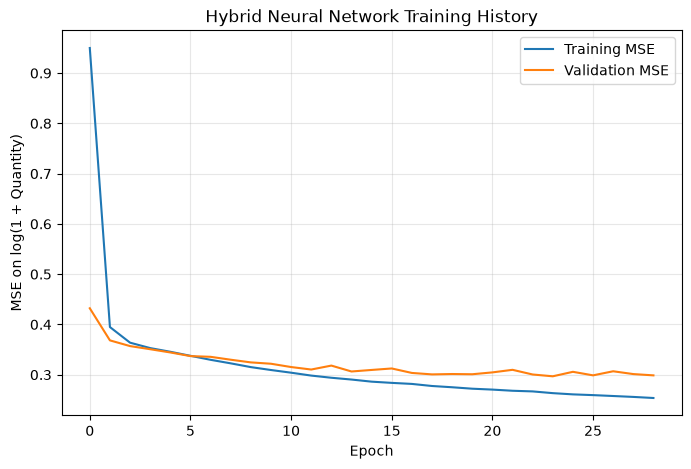

In [52]:
plt.figure(figsize=(8, 5))

plt.plot(
    hybrid_train_losses,
    label="Training MSE"
)

plt.plot(
    hybrid_val_losses,
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("MSE on log(1 + Quantity)")
plt.title("Hybrid Neural Network Training History")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [53]:
hybrid_model.eval()

hybrid_predictions_log = []

with torch.no_grad():

    for stock, customer, te, target in hybrid_test_loader:

        stock = stock.to(device)
        customer = customer.to(device)
        te = te.to(device)

        prediction = hybrid_model(
            stock,
            customer,
            te
        )

        hybrid_predictions_log.append(
            prediction.cpu().numpy()
        )

hybrid_predictions_log = np.concatenate(
    hybrid_predictions_log
)

hybrid_predictions = np.maximum(
    np.expm1(hybrid_predictions_log),
    0
)

In [54]:
hybrid_mae = mean_absolute_error(
    y_test_original,
    hybrid_predictions
)

hybrid_rmse = np.sqrt(
    mean_squared_error(
        y_test_original,
        hybrid_predictions
    )
)

hybrid_rmsle = np.sqrt(
    mean_squared_error(
        np.log1p(y_test_original),
        np.log1p(hybrid_predictions)
    )
)

print("Hybrid Neural Network Results")

print("Test MAE:", hybrid_mae)
print("Test RMSE:", hybrid_rmse)
print("Test RMSLE:", hybrid_rmsle)

Hybrid Neural Network Results
Test MAE: 6.416500568389893
Test RMSE: 32.376626934869044
Test RMSLE: 0.547170990019707


In [55]:
q2d_results = pd.DataFrame({
    "Model": ["Hybrid NN"],
    "Test MAE": [hybrid_mae],
    "Test RMSE": [hybrid_rmse],
    "Test RMSLE": [hybrid_rmsle]
})

comparison_q2 = pd.concat(
    [
        q2b_results,
        q2c_results,
        q2d_results
    ],
    ignore_index=True
)

display(comparison_q2.round(4))

,Model,Test MAE,Test RMSE,Test RMSLE
0,Target Encoding + Ridge,6.9783,34.5287,0.6014
1,Embedding NN,6.2044,30.3253,0.5393
2,Hybrid NN,6.4165,32.3766,0.5472


The hybrid model achieved a test MAE of 6.417, RMSE of 32.377, and RMSLE of 0.547. Compared with the target encoding and embedding-only models, the hybrid model performed better than target encoding model, but worse than embedding neural network model. This suggests that the target-encoded statistics did not provide useful additional information beyond the learned embeddings.

(e)

The Embedding NN achieved the best performance among the three models, with a test MAE of 6.2044, RMSE of 30.3253 and RMSLE of 0.5393. It outperformed the target encoding model, which achieved an MAE of 6.9783, RMSE of 34.5287 and RMSLE of 0.6014.

The embedding layers map each StockCode and CustomerID to a trainable 16-dimensional vector. These representations are learned through backpropagation, which allowed the neural network to capture relationships between products, customers and purchase quantities. This is useful for high-cardinality categorical features.

The Hybrid NN achieved an MAE of 6.4165, RMSE of 32.3766 and RMSLE of 0.5472. Although it performed better than the target encoding model, it did not outperform the Embedding NN. One possible reason is that the embeddings had already captured most of the predictive information by target encoding.

The relatively large RMSE values can be explained by the heavy-tailed distribution of quantity, because RMSE is sensitive to large prediction errors.

**Question 3**

(a)

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("val.csv")
test_df = pd.read_csv("test.csv")

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())

Training shape: (600, 3)
Validation shape: (200, 3)
Test shape: (200, 2)


,x1,x2,y
0,1.178815,-1.283164,1.752019
1,-1.638891,0.307889,-0.682641
2,1.316814,-0.461361,1.091145
3,2.884585,1.108978,0.918561
4,-0.114409,-0.647295,-0.187220


In [57]:
X_train = train_df[["x1", "x2"]].to_numpy()
y_train = train_df["y"].to_numpy()

X_val = val_df[["x1", "x2"]].to_numpy()
y_val = val_df["y"].to_numpy()

X_test = test_df[["x1", "x2"]].to_numpy()

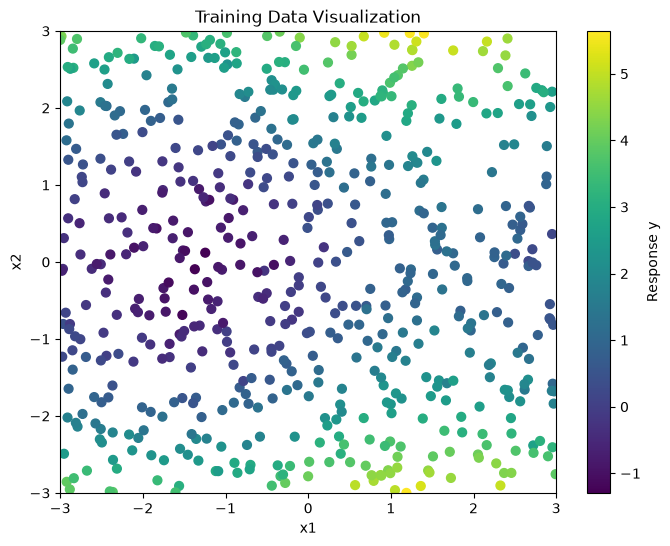

In [58]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    cmap="viridis",
    s=40
)

plt.colorbar(scatter, label="Response y")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Training Data Visualization")

plt.xlim(-3, 3)
plt.ylim(-3, 3)

plt.show()

(b)

In [59]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

h = 50
sigma = 1.0

rng = np.random.default_rng(42)

W = rng.normal(
    loc=0,
    scale=1 / sigma,
    size=(2, h)
)

b = rng.uniform(
    low=0,
    high=2 * np.pi,
    size=h
)

print("W shape:", W.shape)
print("b shape:", b.shape)

W shape: (2, 50)
b shape: (50,)


In [60]:
projection_train = X_train @ W + b

sin_train = np.sin(projection_train)
cos_train = np.cos(projection_train)

Z_train = np.concatenate(
    [sin_train, cos_train],
    axis=1
)

print("Original X:", X_train.shape)
print("RKS Features:", Z_train.shape)

projection_val = X_val @ W + b

Z_val = np.concatenate(
    [
        np.sin(projection_val),
        np.cos(projection_val)
    ],
    axis=1
)

print("Validation Features:", Z_val.shape)

Original X: (600, 2)
RKS Features: (600, 100)
Validation Features: (200, 100)


In [61]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(
    Z_train,
    y_train
)

train_pred = ridge_model.predict(Z_train)

val_pred = ridge_model.predict(Z_val)

In [62]:
train_mse = mean_squared_error(
    y_train,
    train_pred
)

val_mse = mean_squared_error(
    y_val,
    val_pred
)

print("Training MSE:", train_mse)
print("Validation MSE:", val_mse)

Training MSE: 0.033911875991323594
Validation MSE: 0.03665251477384459


In [63]:
class RandomKitchenSinks:

    def __init__(
        self,
        h=50,
        sigma=1.0,
        ridge_lambda=0.001,
        random_state=42
    ):

        self.h = h
        self.sigma = sigma
        self.ridge_lambda = ridge_lambda
        self.random_state = random_state

    def _features(self, X):

        projection = X @ self.W + self.b

        Z = np.concatenate(
            [
                np.sin(projection),
                np.cos(projection)
            ],
            axis=1
        )

        return Z

    def fit(self, X, y):

        rng = np.random.default_rng(
            self.random_state
        )

        self.W = rng.normal(
            loc=0,
            scale=1 / self.sigma,
            size=(X.shape[1], self.h)
        )

        self.b = rng.uniform(
            0,
            2 * np.pi,
            size=self.h
        )

        Z = self._features(X)

        self.model = Ridge(
            alpha=len(X) * self.ridge_lambda
        )

        self.model.fit(Z, y)

        return self

    def predict(self, X):

        Z = self._features(X)

        return self.model.predict(Z)

In [64]:
h_values = [10, 20, 40, 80, 160]

train_losses = []
val_losses = []

models = []

for h in h_values:

    model = RandomKitchenSinks(
        h=h,
        sigma=1.0,
        ridge_lambda=0.001,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_mse = mean_squared_error(
        y_train,
        train_pred
    )

    val_mse = mean_squared_error(
        y_val,
        val_pred
    )

    train_losses.append(train_mse)
    val_losses.append(val_mse)

    models.append(model)

    print(
        f"h={h}, D={2*h} | "
        f"Train MSE={train_mse:.4f} | "
        f"Val MSE={val_mse:.4f}"
    )

h=10, D=20 | Train MSE=0.0706 | Val MSE=0.0706
h=20, D=40 | Train MSE=0.0365 | Val MSE=0.0392
h=40, D=80 | Train MSE=0.0332 | Val MSE=0.0371
h=80, D=160 | Train MSE=0.0314 | Val MSE=0.0377
h=160, D=320 | Train MSE=0.0304 | Val MSE=0.0384


In [65]:
import pandas as pd

results = pd.DataFrame({
    "h": h_values,
    "D": [2*h for h in h_values],
    "Train MSE": train_losses,
    "Validation MSE": val_losses
})

display(results)

,h,D,Train MSE,Validation MSE
0,10,20,0.070591,0.070648
1,20,40,0.036482,0.039159
2,40,80,0.033193,0.037112
3,80,160,0.031416,0.037652
4,160,320,0.030412,0.038438


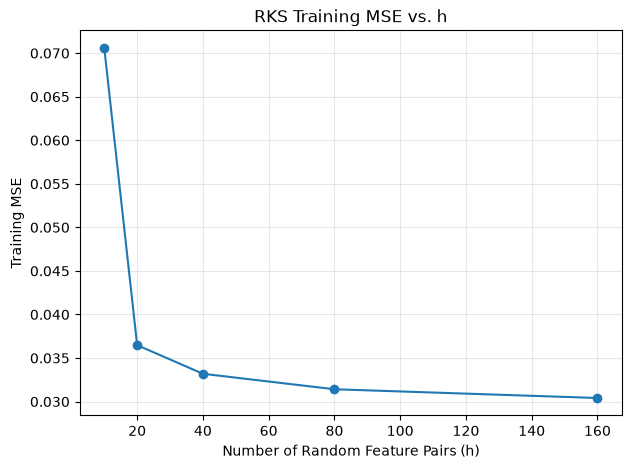

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(
    h_values,
    train_losses,
    marker="o"
)

plt.xlabel("Number of Random Feature Pairs (h)")
plt.ylabel("Training MSE")
plt.title("RKS Training MSE vs. h")
plt.grid(alpha=0.3)

plt.show()

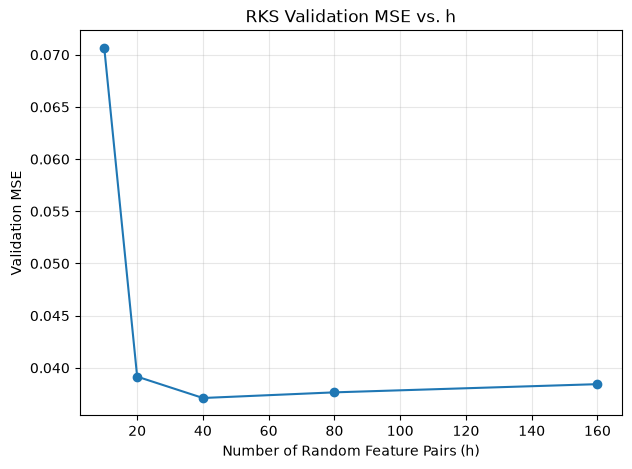

In [67]:
plt.figure(figsize=(7, 5))

plt.plot(
    h_values,
    val_losses,
    marker="o"
)

plt.xlabel("Number of Random Feature Pairs (h)")
plt.ylabel("Validation MSE")
plt.title("RKS Validation MSE vs. h")
plt.grid(alpha=0.3)

plt.show()

In [68]:
best_idx = np.argmin(val_losses)

best_h = h_values[best_idx]

best_model = models[best_idx]

best_val_mse = val_losses[best_idx]

print("Best h:", best_h)
print("Best D:", 2 * best_h)
print("Best Validation MSE:", best_val_mse)

Best h: 40
Best D: 80
Best Validation MSE: 0.03711164704984445


In [69]:
# Best RKS model summary

best_idx = np.argmin(val_losses)
best_D = 2 * best_h

best_train_mse = train_losses[best_idx]
best_val_mse = val_losses[best_idx]

summary = pd.DataFrame({
    "Best h": [best_h],
    "Best D": [best_D],
    "Training MSE": [best_train_mse],
    "Validation MSE": [best_val_mse]
})

display(summary)

print(f"Best RKS configuration: D = {best_D}, h = {best_h}")
print(f"Training MSE: {best_train_mse:.6f}")
print(f"Validation MSE: {best_val_mse:.6f}")

,Best h,Best D,Training MSE,Validation MSE
0,40,80,0.033193,0.037112


Best RKS configuration: D = 80, h = 40
Training MSE: 0.033193
Validation MSE: 0.037112


(c)

In [70]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


class MLP(nn.Module):
    """1-hidden-layer MLP for regression."""

    def __init__(
        self,
        d_in: int,
        d_hidden: int = 128,
        d_out: int = 1,
        lr: float = 1e-3,
        batch_size: int = 128,
        activation: str = "relu",
        device: str = "cpu"
    ):
        super().__init__()

        self.device = device
        self.lr = lr
        self.batch_size = batch_size

        if activation == "relu":
            act = nn.ReLU()
        elif activation == "tanh":
            act = nn.Tanh()
        else:
            raise ValueError("Unsupported activation")

        self.net = nn.Sequential(
            nn.Linear(d_in, d_hidden),
            act,
            nn.Linear(d_hidden, d_out)
        ).to(self.device)

    def fit(self, X: np.ndarray, y: np.ndarray):

        X = torch.from_numpy(
            np.asarray(X)
        ).float().to(self.device)

        y = torch.from_numpy(
            np.asarray(y)
        ).float().view(-1, 1).to(self.device)

        dataset = TensorDataset(X, y)

        loader = DataLoader(
            dataset,
            batch_size=self.batch_size,
            shuffle=True
        )

        optimizer = torch.optim.Adam(
            self.net.parameters(),
            lr=self.lr
        )

        loss_fn = nn.MSELoss()

        num_epochs = 500

        self.net.train()

        for epoch in range(num_epochs):

            for X_batch, y_batch in loader:
                optimizer.zero_grad()
                y_pred = self.net(X_batch)
                loss = loss_fn(y_pred, y_batch)
                loss.backward()
                optimizer.step()

        return self

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        return self.net(X)

    def predict(self, X: np.ndarray) -> np.ndarray:

        self.net.eval()

        with torch.no_grad():
            X = torch.from_numpy(
                np.asarray(X)
            ).float().to(self.device)

            predictions = self.forward(X)

            return predictions.cpu().numpy().ravel()

In [71]:
def mlp_sweep(
    sweep_values,
    X_train,
    y_train,
    X_val,
    y_val
):
    best_model = None
    best_val_mse = float("inf")
    best_hidden = None

    train_losses = []
    val_losses = []

    for d_hidden in sweep_values:

        torch.manual_seed(42)

        model = MLP(
            d_in=2,
            d_hidden=d_hidden,
            d_out=1,
            lr=1e-3,
            batch_size=128,
            activation="relu",
            device="cpu"
        )

        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)

        train_mse = np.mean(
            (y_train.ravel() - train_pred) ** 2
        )

        val_mse = np.mean(
            (y_val.ravel() - val_pred) ** 2
        )

        train_losses.append(train_mse)
        val_losses.append(val_mse)

        print(
            f"Hidden={d_hidden} | "
            f"Train MSE={train_mse:.6f} | "
            f"Val MSE={val_mse:.6f}"
        )

        if val_mse < best_val_mse:
            best_model = model
            best_val_mse = val_mse
            best_hidden = d_hidden

    return (
        best_model,
        best_val_mse,
        best_hidden,
        train_losses,
        val_losses
    )

In [72]:
hidden_values = [16, 32, 64, 128]

(
    best_mlp,
    best_mlp_val_mse,
    best_hidden,
    mlp_train_losses,
    mlp_val_losses
) = mlp_sweep(
    hidden_values,
    X_train,
    y_train,
    X_val,
    y_val
)

print("Best Hidden Dimension:", best_hidden)
print("Best Validation MSE:", best_mlp_val_mse)

/var/folders/5w/q39y2cc543s74f6897gtf43c0000gn/T/ipykernel_68070/3044949393.py:45: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  y = torch.from_numpy(


Hidden=16 | Train MSE=0.116737 | Val MSE=0.124909
Hidden=32 | Train MSE=0.044910 | Val MSE=0.049892
Hidden=64 | Train MSE=0.036005 | Val MSE=0.043248
Hidden=128 | Train MSE=0.032031 | Val MSE=0.039583
Best Hidden Dimension: 128
Best Validation MSE: 0.03958325473602052


In [73]:
mlp_results = pd.DataFrame({
    "Hidden Dimension": hidden_values,
    "Training MSE": mlp_train_losses,
    "Validation MSE": mlp_val_losses
})

display(mlp_results)

,Hidden Dimension,Training MSE,Validation MSE
0,16,0.116737,0.124909
1,32,0.044910,0.049892
2,64,0.036005,0.043248
3,128,0.032031,0.039583


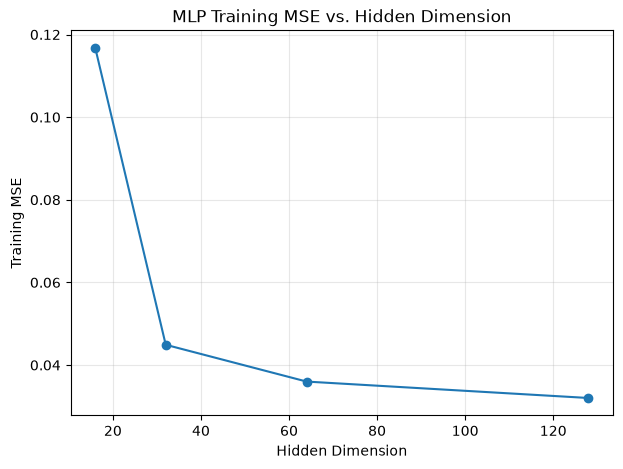

In [74]:
plt.figure(figsize=(7, 5))

plt.plot(
    hidden_values,
    mlp_train_losses,
    marker="o"
)

plt.xlabel("Hidden Dimension")
plt.ylabel("Training MSE")
plt.title("MLP Training MSE vs. Hidden Dimension")
plt.grid(alpha=0.3)

plt.show()

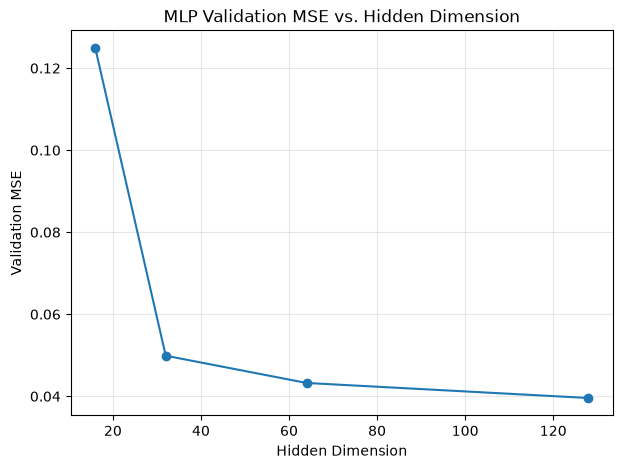

In [75]:
plt.figure(figsize=(7, 5))

plt.plot(
    hidden_values,
    mlp_val_losses,
    marker="o"
)

plt.xlabel("Hidden Dimension")
plt.ylabel("Validation MSE")
plt.title("MLP Validation MSE vs. Hidden Dimension")
plt.grid(alpha=0.3)

plt.show()

In [76]:
best_idx = np.argmin(mlp_val_losses)

print("Best Hidden Dimension:", best_hidden)
print(f"Training MSE: {mlp_train_losses[best_idx]:.6f}")
print(f"Validation MSE: {best_mlp_val_mse:.6f}")

print("\nBest MLP Architecture:")
print(best_mlp.net)

Best Hidden Dimension: 128
Training MSE: 0.032031
Validation MSE: 0.039583

Best MLP Architecture:
Sequential(
  (0): Linear(in_features=2, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=1, bias=True)
)


(d)

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

best_h = 40

best_rks = RandomKitchenSinks(
    h=best_h,
    sigma=1.0,
    ridge_lambda=0.001,
    random_state=42
)

best_rks.fit(X_train, y_train)

rks_train_pred = best_rks.predict(X_train)
rks_val_pred = best_rks.predict(X_val)

rks_train_mse = np.mean(
    (y_train - rks_train_pred) ** 2
)

rks_val_mse = np.mean(
    (y_val - rks_val_pred) ** 2
)

print("RKS Training MSE:", rks_train_mse)
print("RKS Validation MSE:", rks_val_mse)

RKS Training MSE: 0.03319255650214332
RKS Validation MSE: 0.03711164704984445


In [78]:
torch.manual_seed(42)

best_mlp = MLP(
    d_in=2,
    d_hidden=best_hidden,
    d_out=1,
    lr=0.001,
    batch_size=128,
    activation="relu",
    device="cpu"
)

best_mlp.fit(X_train, y_train)

mlp_train_pred = best_mlp.predict(X_train)
mlp_val_pred = best_mlp.predict(X_val)

mlp_train_mse = np.mean(
    (y_train - mlp_train_pred) ** 2
)

mlp_val_mse = np.mean(
    (y_val - mlp_val_pred) ** 2
)

print("MLP Training MSE:", mlp_train_mse)
print("MLP Validation MSE:", mlp_val_mse)

MLP Training MSE: 0.03203054705247864
MLP Validation MSE: 0.03958325473602052


In [79]:
comparison = pd.DataFrame({
    "Model": ["RKS", "MLP"],
    "Training MSE": [
        rks_train_mse,
        mlp_train_mse
    ],
    "Validation MSE": [
        rks_val_mse,
        mlp_val_mse
    ]
})

display(comparison)

if rks_val_mse < mlp_val_mse:
    print("Best Model: RKS")
elif mlp_val_mse < rks_val_mse:
    print("Best Model: MLP")
else:
    print("Both models have the same Validation MSE")

,Model,Training MSE,Validation MSE
0,RKS,0.033193,0.037112
1,MLP,0.032031,0.039583


Best Model: RKS


The RKS model achieved a training MSE of 0.033193 and a validation MSE of 0.037112, while the MLP achieved a training MSE of 0.032031 and a validation MSE of 0.039583. Although the MLP achieved a slightly lower training MSE, the RKS model performed better on the validation set, with approximately 6.2% lower validation MSE. This means that RKS performed better in validation.

In [80]:
test_df = pd.read_csv("test.csv")

X_test = test_df[["x1", "x2"]].to_numpy()

rks_test_pred = best_rks.predict(X_test)
mlp_test_pred = best_mlp.predict(X_test)

print("RKS predictions shape:", rks_test_pred.shape)
print("MLP predictions shape:", mlp_test_pred.shape)

RKS predictions shape: (200,)
MLP predictions shape: (200,)


In [81]:
pd.DataFrame({
    "y": rks_test_pred
}).to_csv(
    "rks_test_predictions.csv",
    index=False
)

pd.DataFrame({
    "y": mlp_test_pred
}).to_csv(
    "mlp_test_predictions.csv",
    index=False
)

print("Both prediction files saved successfully.")

Both prediction files saved successfully.


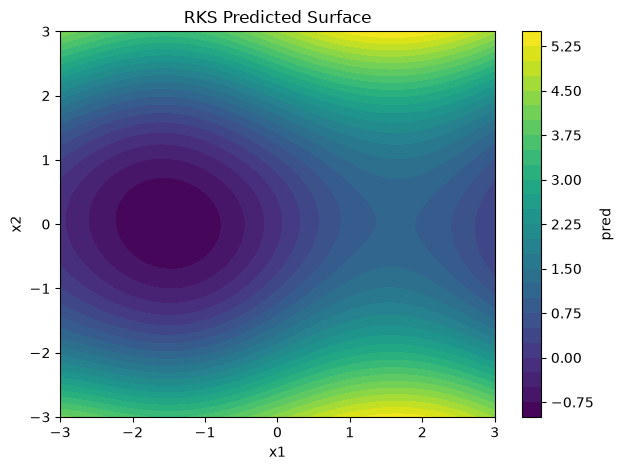

In [82]:
from plotting import plot_surface_2d

plot_surface_2d(
    best_rks.predict,
    xlim=(-3, 3),
    ylim=(-3, 3),
    title="RKS Predicted Surface",
    filename="rks_surface.png",
    grid=200
)

plt.show()

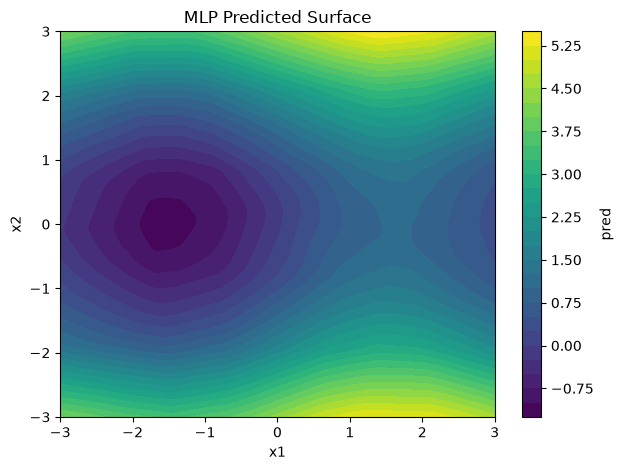

In [83]:
plot_surface_2d(
    best_mlp,
    xlim=(-3, 3),
    ylim=(-3, 3),
    title="MLP Predicted Surface",
    filename="mlp_surface.png",
    grid=200
)

plt.show()

Both predicted surfaces captured the nonlinear patterns observed in part a, because from the graphs, the curved contour lines indicate that the fitted surface is not a linear plane. The predicted response is lower when x2 is near zero and higher when x2 approaches to -3 or 3. The predicted response is also lower around x1 = -1.5 and generally increases when x1 increases. In addition, the RKS model produced a smoother prediction surface. Overall, the trends of both predicted surfaces are consistent with those observed in the training data in part a.